# El Motor de Recomendación de "GameStore" 🎮
Contexto del Negocio:
Han sido contratados por "GameStore", una tienda local de videojuegos. El gerente quiere rediseñar su sitio web e implementar la función: "Los usuarios que compraron esto, también llevaron...".

Su misión es analizar las transacciones del fin de semana, aplicar el algoritmo de Reglas de Asociación y decidir qué productos deben recomendarse activamente en la pantalla de pago (Checkout).

## Fase 1: Los Tickets de Compra
A continuación, se presenta la lista de compras del fin de semana. Nuestro catálogo principal incluye Consolas, Controles, Juegos y Suscripciones.

In [37]:
# Importamos las librerías necesarias
import pandas as pd
import seaborn as sns
from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules 

# 1. DATOS DE PRODUCCIÓN (Listas de compras)
tickets_gaming = [
    ['Consola PS5', 'Control Extra', 'FIFA 26'],
    ['Consola PS5', 'Suscripción Plus', 'Cable USB-C'],
    ['Control Extra', 'Cable USB-C'],
    ['Consola PS5', 'Control Extra', 'Suscripción Plus'],
    ['Control Extra', 'FIFA 26'],
    ['Consola PS5', 'Control Extra', 'Cable USB-C'],
    ['Cable USB-C', 'Suscripción Plus'],
    ['Control Extra'],
    ['Consola PS5', 'Control Extra', 'FIFA 26', 'Suscripción Plus'],
    ['Control Extra', 'Funda de Silicon']
]
# 5 ps5'set
# 8 controles extra
# 4 subs plus
# 3 fifas
# 1 funda silicon

# --- RETO 1: TRANSFORMACIÓN (Escribe tu código abajo) ---
# Convierte la lista 'tickets_gaming' en un DataFrame booleano llamado 'df_tienda'
# usando TransactionEncoder.

te = TransactionEncoder()
df_tienda = pd.DataFrame(te.fit(tickets_gaming).transform(tickets_gaming), columns=te.columns_)

print("--- MATRIZ TRANSACCIONAL ---")
display(df_tienda)

--- MATRIZ TRANSACCIONAL ---


,Cable USB-C,Consola PS5,Control Extra,FIFA 26,Funda de Silicon,Suscripción Plus
0,False,True,True,True,False,False
1,True,True,False,False,False,True
2,True,False,True,False,False,False
3,False,True,True,False,False,True
4,False,False,True,True,False,False
5,True,True,True,False,False,False
6,True,False,False,False,False,True
7,False,False,True,False,False,False
8,False,True,True,True,False,True
9,False,False,True,False,True,False


### Fase 2: Extracción de Reglas y Filtrado Direccional
Vamos a generar todas las reglas posibles con un Soporte mínimo del 20% (0.2) y una Confianza mínima del 40% (0.4).

In [38]:
# --- RETO 2: EXTRACCIÓN (Escribe tu código abajo) ---

# 1. Genera los itemsets frecuentes (min_support = 0.2)
itemsets = apriori(df_tienda, min_support=0.2, use_colnames=True)

# 2. Genera las reglas de asociación (metric = 'confidence', min_threshold = 0.4)
reglas_store = association_rules(itemsets, metric='confidence', min_threshold=0.4)

# Creamos columnas auxiliares de texto para facilitar el filtrado de Pandas
reglas_store['ant_str'] = reglas_store['antecedents'].apply(lambda x: ', '.join(list(x)))
reglas_store['con_str'] = reglas_store['consequents'].apply(lambda x: ', '.join(list(x)))

print("--- TOP 5 REGLAS POR CONFIANZA ---")
# Muestra las 5 reglas con mayor confianza
display(reglas_store.sort_values(by='confidence', ascending=False).head())

--- TOP 5 REGLAS POR CONFIANZA ---


,antecedents,consequents,antecedent support,consequent support,support,confidence,lift,representativity,leverage,conviction,zhangs_metric,jaccard,certainty,kulczynski,ant_str,con_str
18,"(Control Extra, Suscripción Plus)",(Consola PS5),0.2,0.5,0.2,1.00,2.00,1.0,0.10,inf,0.625000,0.400000,1.0,0.7000,"Control Extra, Suscripción Plus",Consola PS5
11,(FIFA 26),(Control Extra),0.3,0.8,0.3,1.00,1.25,1.0,0.06,inf,0.285714,0.375000,1.0,0.6875,FIFA 26,Control Extra
14,"(FIFA 26, Consola PS5)",(Control Extra),0.2,0.8,0.2,1.00,1.25,1.0,0.04,inf,0.250000,0.250000,1.0,0.6250,"FIFA 26, Consola PS5",Control Extra
6,(Consola PS5),(Control Extra),0.5,0.8,0.4,0.80,1.00,1.0,0.00,1.0,0.000000,0.444444,0.0,0.6500,Consola PS5,Control Extra
9,(Suscripción Plus),(Consola PS5),0.4,0.5,0.3,0.75,1.50,1.0,0.10,2.0,0.555556,0.500000,0.5,0.6750,Suscripción Plus,Consola PS5


### Fase 3: La Batalla Direccional (PS5 vs Control Extra)

El gerente tiene una duda específica: *"Si alguien mete una Consola PS5 al carrito, ¿debo recomendarle un Control Extra? ¿Y si alguien mete un Control Extra, le recomiendo la Consola PS5?"*

Filtra tu tabla `reglas_store` para aislar exclusivamente la interacción entre estos dos productos y comparar sus métricas.

In [39]:
# --- RETO 3: EL FILTRO (Escribe tu código abajo) ---
# Crea un DataFrame llamado 'dilema_ps5' filtrando 'reglas_store' donde:
# (ant_str == 'Consola PS5' Y con_str == 'Control Extra') 
# O (ant_str == 'Control Extra' Y con_str == 'Consola PS5')

dilema_ps5 = reglas_store[
    ((reglas_store['ant_str'] == 'Consola PS5') & (reglas_store['con_str'] == 'Control Extra')) |
    ((reglas_store['ant_str'] == 'Control Extra') & (reglas_store['con_str'] == 'Consola PS5'))
]

print("--- ANÁLISIS DIRECCIONAL (Consola vs Control) ---")
display(dilema_ps5[['antecedents', 'consequents', 'support', 'confidence', 'lift']])

--- ANÁLISIS DIRECCIONAL (Consola vs Control) ---


,antecedents,consequents,support,confidence,lift
5,(Control Extra),(Consola PS5),0.4,0.5,1.0
6,(Consola PS5),(Control Extra),0.4,0.8,1.0


### 🧠 Fase 4: Toma de Decisiones (Responde aquí mismo)

Revisa el resultado del Reto 3 y responde al gerente con argumentos basados en datos:

**1. Interpretación de Confianza Asimétrica:**
Observa la diferencia de Confianza entre comprar la Consola $\rightarrow$ Control, frente a comprar el Control $\rightarrow$ Consola. Explica con lógica de negocio o comportamiento del consumidor por qué ocurre esta asimetría tan grande en los porcentajes.
> **Tu Respuesta:** Comprando la consola y después el control tiene una lógica creible, considerando que puede ser que lo hayan comprado para juegos de dos jugadores, mientras comprando un control y después la consola no motiva al usuario tener la consola pero lo considera mas como algo extra.

**2. Diseño del Sistema de Recomendación:**
Basado en los datos, si un cliente está a punto de pagar únicamente un **Control Extra** en su carrito de compras, ¿sería una buena idea que el sistema lance un *Pop-up* recomendándole comprar una Consola PS5? Justifica usando las métricas descubiertas.
> **Tu Respuesta:** No es una buena idea porque si consideramos que es un control extra, se puede concluir que existe una asociación inversa débil, por lo que el sistema debería recomendar la consola cuando ya hay una consola en el carrito o cuando el comportamiento del cliente sugiere la compra del mismo hardware.

### Fase 5: Evaluando el Impacto en Volumen (Leverage)

El *Lift* nos dice qué tan fuerte es la asociación, pero es una proporción. No nos dice cuántas ventas adicionales reales estamos logrando. Para eso existe el **Leverage** (Apalancamiento).

**La Matemática:** $Leverage(A \rightarrow B) = Soporte(A \cap B) - [Soporte(A) \times Soporte(B)]$

El *Leverage* mide la diferencia entre observar A y B juntos en la vida real, frente a lo que esperaríamos si se vendieran de forma totalmente aleatoria. Un valor de 0 indica independencia. Un valor positivo mayor indica más ventas conjuntas "extra".

### Fase 6: Nivel de Dependencia (Conviction)

Por último, el gerente quiere saber si hay accesorios que sean "esclavos" de la venta principal. Para esto usamos la **Convicción** (*Conviction*).

**La Matemática:** $Conviction(A \rightarrow B) = \frac{1 - Soporte(B)}{1 - Confianza(A \rightarrow B)}$

La Convicción evalúa qué tan dependiente es el Consecuente respecto al Antecedente. Un valor alto de convicción significa que es altísimamente improbable que el Antecedente ocurra sin el Consecuente. Si la Confianza es del 100% (1.0), la Convicción será infinita (`inf`).

In [40]:
# --- RETO 5: NIVEL DE DEPENDENCIA (Escribe tu código abajo) ---
# 1. Ordena tu DataFrame 'reglas_store' por la columna 'conviction' de forma descendente.
# 2. Muestra las 3 mejores reglas.

reglas_store = reglas_store.sort_values(by='conviction', ascending=False)

print("--- TOP 3 REGLAS POR CONVICCIÓN (Dependencia del producto) ---")
top_conviction = reglas_store.head(3)
display(top_conviction[['antecedents', 'consequents', 'confidence', 'lift', 'leverage', 'conviction']].head(3))

--- TOP 3 REGLAS POR CONVICCIÓN (Dependencia del producto) ---


,antecedents,consequents,confidence,lift,leverage,conviction
18,"(Control Extra, Suscripción Plus)",(Consola PS5),1.0,2.00,0.10,inf
11,(FIFA 26),(Control Extra),1.0,1.25,0.06,inf
14,"(FIFA 26, Consola PS5)",(Control Extra),1.0,1.25,0.04,inf


### 🧠 Fase 7: El Diagnóstico Final (Responde aquí)

Has utilizado métricas avanzadas que la mayoría de los analistas junior ignoran. Responde las últimas preguntas del gerente de "GameStore":

**1. El Significado del Leverage Positivo:**
En contraste con el Lift (que puede ser un número enorme pero representar solo 1 venta rara), el Leverage se enfoca en el volumen general de la tienda. Si una regla tiene un Leverage de `0.12`, ¿qué le dirías al gerente sobre el impacto de esa combinación en su inventario comparado con si esos productos se vendieran al azar?
> **Tu Respuesta:** Le diría que un leverage de 0.12 indica que la combinación tiene un impacto real y consistente en la tienda, mucho mayor que si los productos se vendieran al azar, por lo que no es una coincidencia aislada.

**2. El Misterio del Infinito:**
Si en tu tabla de Convicción aparece el valor `inf` (infinito) para la regla `(FIFA 26) -> (Control Extra)`, ¿qué significa eso exactamente en el comportamiento de los clientes que entraron a comprar el juego de fútbol este fin de semana? 
> **Tu Respuesta:** Significa que comprar FIFA 26 casi garantiza comprar Control Extra, teniendo en cuenta que casi todos los clientes que compran el juego tambien llevan el accesorio.

### Fase 8: De Asociación a Correlación Estadística (El Engaño de la Confianza)

A veces, una regla tiene alta **Confianza** simplemente porque el producto consecuente es extremadamente popular por sí solo, ocultando el hecho de que ambos productos en realidad se **repelen** (correlación negativa).

Para auditar nuestras reglas con rigor estadístico, usaremos dos técnicas de **Análisis de Correlación**:
1. **La Métrica de Zhang (`zhangs_metric`):** Mide la correlación real entre -1 (repulsión total) y +1 (atracción total), corrigiendo el sesgo de los productos hiper-populares.
2. **La Matriz de Correlación Phi ($\phi$):** El equivalente a la correlación de Pearson pero para matrices booleanas (True/False).

In [43]:
# --- DEMOSTRACIÓN DE LA PARADOJA (Ejecutar y analizar) ---
# Filtramos qué pasa cuando alguien compra 'Funda de Silicon' o 'FIFA 26' hacia los productos populares
paradoja = reglas_store[
    (reglas_store['ant_str'] == 'FIFA 26') | 
    (reglas_store['con_str'] == 'Funda de Silicon') 
]

print("--- ¿IMPULSO REAL O CORRELACIÓN NEGATIVA? ---")
# Observa cómo incluimos 'zhangs_metric' que mlxtend calcula automáticamente
display(paradoja[['antecedents', 'consequents', 'support', 'confidence', 'lift', 'zhangs_metric']])

--- ¿IMPULSO REAL O CORRELACIÓN NEGATIVA? ---


,antecedents,consequents,support,confidence,lift,zhangs_metric
11,(FIFA 26),(Control Extra),0.3,1.000000,1.250000,0.285714
16,(FIFA 26),"(Control Extra, Consola PS5)",0.2,0.666667,1.666667,0.571429
7,(FIFA 26),(Consola PS5),0.2,0.666667,1.333333,0.357143


### Reto 6: La Matriz de Correlación Phi ($\phi$) de la Tienda

Antes de lanzar promociones, el director de datos quiere ver un panorama general de qué productos "se llevan bien" (correlación positiva) y qué productos "compiten o se estorban" (correlación negativa) en toda la tienda.

**Tu tarea:**
1. Calcula la matriz de correlación directamente sobre tu DataFrame booleano `df_tienda` usando el método `.corr()`.
2. Extrae y ordena las correlaciones específicas de la **Consola PS5** contra el resto del catálogo.

--- MATRIZ DE CORRELACIÓN PHI (TODA LA TIENDA) ---


Axes(0.125,0.11;0.62x0.77)

--- CORRELACIÓN CON CONSOLA PS5 ---


Consola PS5         1.000000e+00
Suscripción Plus    4.082483e-01
FIFA 26             2.182179e-01
Cable USB-C         0.000000e+00
Control Extra      -2.081668e-17
Funda de Silicon   -3.333333e-01
Name: Consola PS5, dtype: float64

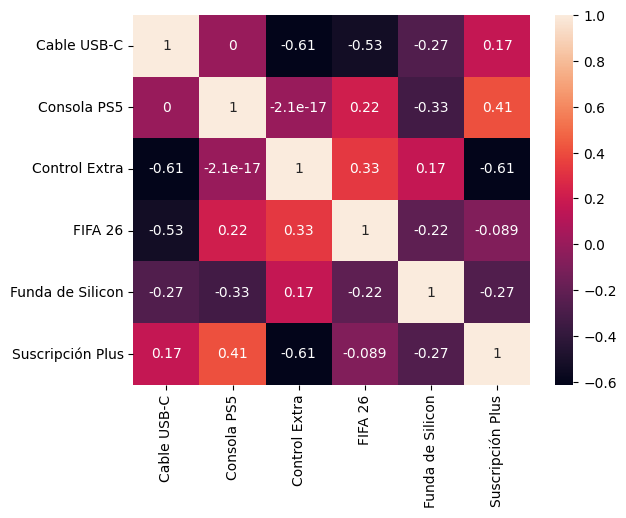

In [ ]:
# --- RETO 6: MATRIZ DE CORRELACIÓN (Escribe tu código abajo) ---

# 1. Calcula la matriz de correlación de df_tienda
matriz_corr = df_tienda.corr()

# 2. Muestra toda la matriz (Opcional: si tienes seaborn, puedes usar sns.heatmap(matriz_corr, annot=True))
print("--- MATRIZ DE CORRELACIÓN PHI (TODA LA TIENDA) ---")
print(sns.heatmap(matriz_corr, annot=True))

# 3. Aísla la columna 'Consola PS5' y ordénala de mayor a menor para ver sus aliados y enemigos
print("\n--- CORRELACIÓN CON CONSOLA PS5 ---")
corr_ps5 = matriz_corr['Consola PS5'].sort_values(ascending=False)
display(corr_ps5)

### 🧠 Fase 9: Defensa de Correlación (Responde aquí)

Analiza tu Matriz de Correlación Phi ($\phi$) y las métricas de Zhang para responder las siguientes preguntas de auditoría:

**1. Productos Sustitutos / Enemigos (Correlación Negativa):**
Observa la correlación entre `Control Extra` y `Cable USB-C` (o entre `Consola PS5` y `Funda de Silicon`). Notarás que tienen valores negativos (ej. `-0.35` o `-0.50`). 
Sin embargo, la regla `Cable USB-C -> Control Extra` apareció en nuestro reporte original con una **Confianza del 50%**. 
¿Por qué es un grave error financiero armar un combo con estos dos productos a pesar de tener 50% de Confianza? Explica usando el concepto de Correlación.
> **Tu Respuesta:** Porque la correlación entre esos productos es negativa, si uno aparece, el otro tiende a desaparecer, indicando que no son complementarios, sino que compiten o se compran en contextos distintos.

**2. Ventaja Operativa en Ingeniería:**
Calcular el algoritmo Apriori en una tienda con 50,000 productos puede colapsar la memoria RAM por la explosión combinatoria. En cambio, calcular `df.corr()` es una operación matricial directa y muy rápida en C++/CUDA. ¿Cómo usarías la matriz de correlación como filtro previo antes de correr Apriori?
> **Tu Respuesta:** Evaluando las combinaciones con correlación alta y positiva, así evitando gastar tiempo computacional y reglas poco rentables o falsas.